# Sprint 1 — BPSK signal, batch MLE, first error-vs-SNR curve

**Sprint-1 deliverable:** a working batch maximum-likelihood delay estimator and its error-vs-SNR curve, with the CRLB
as reference. (The CRLB formula is *used* here and *derived* properly in Sprint 3.)

| Step | Question it answers |
|---|---|
| 1.1 Derivation | what is the optimal way to use a block of data? → maximise a correlation |
| 1.2 Implementation | what exactly does the code compute? |
| 1.3 Noise-free test | is the implementation exact when there is no noise? |
| 1.4 One trial up close | *why* does a threshold exist at all? |
| 1.5 Monte Carlo | how does the error behave over SNR? |
| 1.6 Error distributions | what changes at the threshold — the size or the *type* of error? |

## 1.1 Derivation: the maximum-likelihood estimator is a correlator

**What:** choose the delay $\theta$ that makes the observed data most probable.
**Why:** for large data records the MLE is (asymptotically) unbiased and attains the CRLB — it is the natural benchmark.

The samples are independent Gaussians with mean $s(t_n-\theta)$ and variance $\sigma^2$, so the likelihood is

$$ p(\mathbf r;\theta)=\prod_n \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\Big(-\frac{(r[n]-s(t_n-\theta))^2}{2\sigma^2}\Big). $$

Taking logs and expanding the square:

$$ \ln p(\mathbf r;\theta)= \text{const} - \frac{1}{2\sigma^2}\sum_n r[n]^2
 + \frac{1}{\sigma^2}\underbrace{\Big(\sum_n r[n]\,s(t_n-\theta) - \tfrac12\sum_n s(t_n-\theta)^2\Big)}_{J(\theta)}. $$

The first sum does not depend on $\theta$, so

$$ \boxed{\hat\tau_{\rm ML}=\arg\max_{\theta\in\text{prior window}} J(\theta),\qquad
J(\theta)=\underbrace{\sum_n r[n]\,s(t_n-\theta)}_{\text{correlation with a shifted replica}}-\tfrac12\underbrace{\sum_n s(t_n-\theta)^2}_{\text{replica energy}}} $$

**Interpretation.** Slide a clean replica over the data and pick the shift that matches best — a *matched filter*. The
energy term is (almost) constant because the whole pulse train stays inside the observation window; we keep it so the
estimator is exactly the MLE. Note that $\sigma^2$ has dropped out: the MLE needs **no knowledge of the SNR**.

**Sub-grid refinement.** $J$ is computed on a grid of step $\Delta = 1/64$ chip. Through the best grid point $g$ and its
neighbours we fit a parabola; its vertex is at

$$ \hat\theta = \theta_g + \frac{\Delta}{2}\,\frac{J_{g-1}-J_{g+1}}{J_{g-1}-2J_g+J_{g+1}} , $$

which follows from setting the derivative of the interpolating quadratic to zero.

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

## 1.2 What the code implements
`BatchMLE.__init__` precomputes the replicas $s(t_n-\theta_g)$ for every grid delay; `objective` computes $J$ for all
grid delays at once (one matrix product); `_ml_from_objective` takes the arg-max and applies the parabola formula.

In [2]:
print(inspect.getsource(BatchMLE.objective))
print(inspect.getsource(BatchMLE._ml_from_objective))

    def objective(self, r):
        return r @ self.templates.T - self.half_energy        # (trials, grid)

    def _ml_from_objective(self, j):
        g = np.argmax(j, axis=1)
        rows = np.arange(j.shape[0])
        interior = (g > 0) & (g < j.shape[1] - 1)
        gm, gp = np.clip(g - 1, 0, None), np.clip(g + 1, None, j.shape[1] - 1)
        jm, j0, jp = j[rows, gm], j[rows, g], j[rows, gp]
        den = jm - 2.0 * j0 + jp
        with np.errstate(divide="ignore", invalid="ignore"):
            delta = np.where(interior & (den < 0), 0.5 * (jm - jp) / den, 0.0)
        theta = self.grid[g] + np.clip(delta, -0.5, 0.5) * self.step
        return np.clip(theta, self.grid[0], self.grid[-1])



## 1.3 Noise-free test
With no noise the MLE must return the true delay up to the (tiny) parabolic-interpolation error. We compare that error
with the CRLB at the highest SNR we will simulate (30 dB): it must be negligible, otherwise the high-SNR results would
measure the grid, not the estimator.

In [3]:
cfg = Config()
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))     # same pilot as Sprint 0
mle = BatchMLE(sc)
rng = np.random.default_rng(1)

tau = sc.draw_delays(2000, rng)
err0 = mle.estimate(sc.wave(sc.t[None, :] - tau[:, None])) - tau
print(f"noise-free MSE = {np.mean(err0**2):.2e} chips^2  =  {np.mean(err0**2) / crlb(sc, 1e3):.2%} of the CRLB at 30 dB")

noise-free MSE = 4.26e-08 chips^2  =  0.02% of the CRLB at 30 dB


## 1.4 One trial up close — *why* a threshold exists

We plot $J(\theta)$ across the whole prior window for one noisy observation at a high and at a low SNR.
At high SNR there is one clear peak at the true delay. At low SNR noise creates competing bumps; whenever one of them
is higher than the true peak, the MLE jumps there — an error of chips, not fractions of a chip. **This is the threshold
mechanism.** The CRLB only describes the shape of the *true* peak, so it cannot see these jumps.

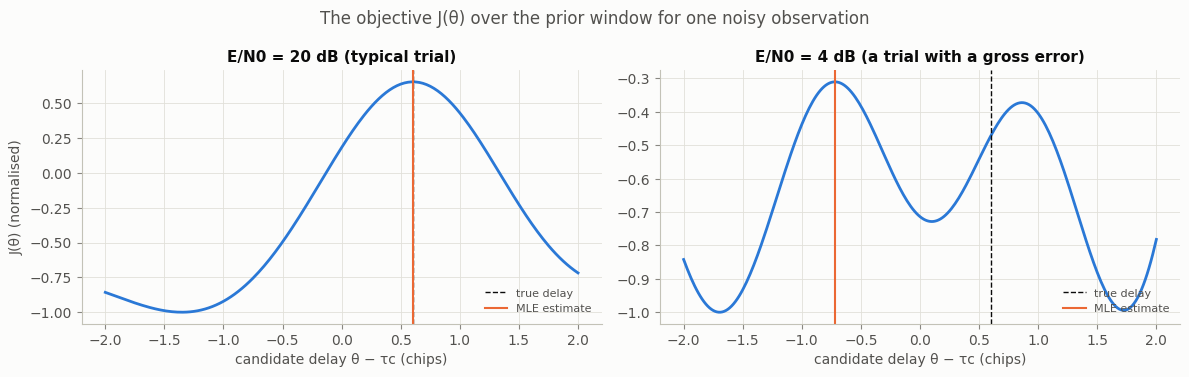

In [4]:
t0 = np.array([sc.tau_c + 0.6])                      # true delay for this illustration
g = np.random.default_rng(3)
r_hi = sc.observe(t0, 10 ** 2.0, g)                   # 20 dB: a typical trial
# 4 dB: about 1 trial in 5 is a gross error. We deliberately SEARCH for one to show the mechanism.
for seed in range(1000):
    r_lo = sc.observe(t0, 10 ** 0.4, np.random.default_rng(seed))
    if abs(mle.estimate(r_lo)[0] - t0[0]) > 1.0:
        break
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, r, title in zip(ax, (r_hi, r_lo), ("E/N0 = 20 dB (typical trial)", "E/N0 = 4 dB (a trial with a gross error)")):
    J = mle.objective(r)[0]
    a.plot(mle.grid - sc.tau_c, J / np.max(np.abs(J)), color=COLORS["mle"])
    a.axvline(t0[0] - sc.tau_c, color=COLORS["crlb"], ls="--", lw=1, label="true delay")
    a.axvline(mle.estimate(r)[0] - sc.tau_c, color=COLORS["dll"], lw=1.5, label="MLE estimate")
    a.set_title(title); a.set_xlabel("candidate delay θ − τc (chips)")
    a.legend(loc="lower right", fontsize=8)
ax[0].set_ylabel("J(θ) (normalised)")
fig.suptitle("The objective J(θ) over the prior window for one noisy observation", color=INK2)
fig.tight_layout(); fig.savefig(FIG + "s1_objective_one_trial.png")

## 1.5 Monte Carlo: MSE versus SNR

**Experiment.** For each $E/N_0$ from −10 to 30 dB (2 dB steps) we draw 2000 independent trials: a random delay from
the prior, fresh noise, one MLE estimate. We record the error $e=\hat\tau-\tau$ and report
$\text{MSE} = \frac1N\sum e_i^2$.

**References on the plot.**
* the **CRLB** $=1/(2\,\tfrac{E}{N_0}\,\beta^2)$ (derived in Sprint 3);
* the **prior variance** $T_a^2/12$: the error of always answering the centre of the window, i.e. using no data.

*Runtime: about 1 minute.*

In [5]:
snr_db = np.arange(-10.0, 32.0, 2.0)
en0 = 10 ** (snr_db / 10)
N = 2000
err = np.empty((snr_db.size, N))
for i, e in enumerate(en0):
    tau = sc.draw_delays(N, rng)
    for c in range(0, N, 500):                      # in chunks to keep memory small
        sl = slice(c, c + 500)
        err[i, sl] = mle.estimate(sc.observe(tau[sl], e, rng)) - tau[sl]
mse = np.mean(err ** 2, axis=1)
cr = crlb(sc, en0)
np.savez(DATA + "s1_mle.npz", snr_db=snr_db, err=err)   # reused by Sprints 3-4

print(" E/N0   MSE (chips^2)   CRLB       MSE/CRLB   P(|e|>0.5 chip)")
for d, m, c, e_ in zip(snr_db, mse, cr, err):
    print(f"{d:5.0f}   {m:10.3e}   {c:10.3e}   {m / c:7.2f}    {np.mean(np.abs(e_) > 0.5):6.3f}")

 E/N0   MSE (chips^2)   CRLB       MSE/CRLB   P(|e|>0.5 chip)
  -10    2.501e+00    2.042e+00      1.22     0.667
   -8    2.413e+00    1.289e+00      1.87     0.642
   -6    2.323e+00    8.131e-01      2.86     0.612
   -4    1.892e+00    5.130e-01      3.69     0.520
   -2    1.639e+00    3.237e-01      5.06     0.458
    0    1.372e+00    2.042e-01      6.72     0.392
    2    9.590e-01    1.289e-01      7.44     0.269
    4    5.885e-01    8.131e-02      7.24     0.187
    6    3.033e-01    5.130e-02      5.91     0.087
    8    8.223e-02    3.237e-02      2.54     0.021
   10    3.759e-02    2.042e-02      1.84     0.008
   12    1.378e-02    1.289e-02      1.07     0.000
   14    8.230e-03    8.131e-03      1.01     0.000
   16    5.030e-03    5.130e-03      0.98     0.000
   18    3.261e-03    3.237e-03      1.01     0.000
   20    1.959e-03    2.042e-03      0.96     0.000
   22    1.317e-03    1.289e-03      1.02     0.000
   24    8.136e-04    8.131e-04      1.00     0.000
  

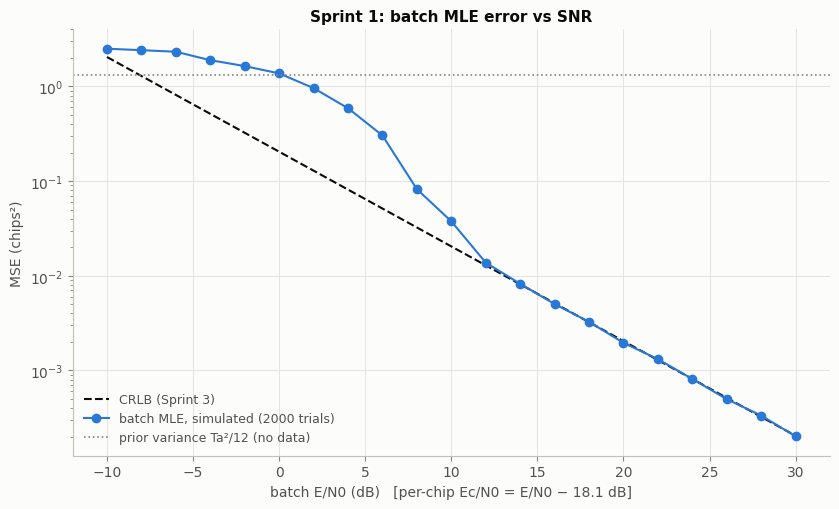

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
xf = np.linspace(snr_db[0], snr_db[-1], 300)
ax.semilogy(xf, crlb(sc, 10 ** (xf / 10)), color=COLORS["crlb"], ls="--", lw=1.5, label="CRLB (Sprint 3)")
ax.semilogy(snr_db, mse, "o-", color=COLORS["mle"], lw=1.5, label="batch MLE, simulated (2000 trials)")
ax.axhline(prior_variance(cfg), color=COLORS["prior"], ls=":", lw=1.2, label="prior variance Ta²/12 (no data)")
ax.set_xlabel("batch E/N0 (dB)   [per-chip Ec/N0 = E/N0 − 18.1 dB]")
ax.set_ylabel("MSE (chips²)")
ax.set_title("Sprint 1: batch MLE error vs SNR")
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(FIG + "s1_mle_mse_vs_snr.png")

## 1.6 Error distributions — what actually changes at the threshold
Histograms of $e$ (log count) at a high SNR, near the break-away, and below it.

MLE on pure noise: MSE = 3.09 chips^2 (prior variance 1.33); 20% of estimates sit exactly on a window edge


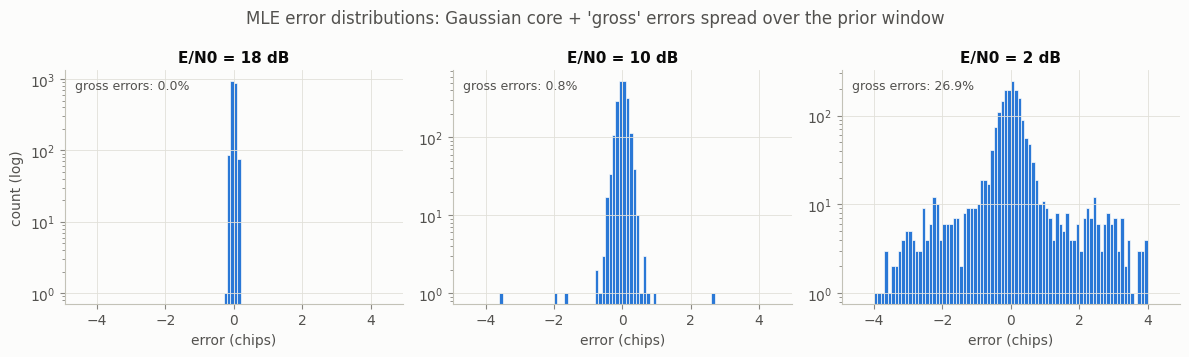

In [7]:
picks = [18.0, 10.0, 2.0]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
bins = np.linspace(-4.5, 4.5, 91)
for a, db in zip(ax, picks):
    i = int(np.argmin(np.abs(snr_db - db)))
    a.hist(err[i], bins=bins, color=COLORS["mle"], edgecolor="#fcfcfb", linewidth=0.5)
    a.set_yscale("log"); a.set_title(f"E/N0 = {snr_db[i]:.0f} dB"); a.set_xlabel("error (chips)")
    gross = np.mean(np.abs(err[i]) > 0.5)
    a.text(0.03, 0.92, f"gross errors: {gross:.1%}", transform=a.transAxes, color=INK2, fontsize=9)
ax[0].set_ylabel("count (log)")
fig.suptitle("MLE error distributions: Gaussian core + 'gross' errors spread over the prior window", color=INK2)
fig.tight_layout(); fig.savefig(FIG + "s1_mle_error_hist.png")

tau = sc.draw_delays(4000, rng)
th = mle.estimate(sc.observe(tau, 1e-8, rng))           # essentially pure noise
edge = np.mean((th <= mle.grid[0]) | (th >= mle.grid[-1]))
print(f"MLE on pure noise: MSE = {np.mean((th - tau)**2):.2f} chips^2 (prior variance {prior_variance(cfg):.2f}); "
      f"{edge:.0%} of estimates sit exactly on a window edge")

## 1.7 Results and what they mean

**Three regimes are visible.**

1. **High SNR (above ≈ 12 dB): the MLE sits on the CRLB** (MSE/CRLB ≈ 1 in the table). Errors are small and Gaussian
   (left histogram). This is the "local" regime: the estimate always lands on the true peak of $J$.
2. **Threshold region (≈ 6–12 dB): the MSE breaks away from the CRLB.** The histogram (middle) shows *why*: the core
   is still narrow, but a small fraction of **gross errors** (|e| > 0.5 chip, i.e. outside the correlation main lobe)
   appears. A 1 % rate of 2-chip errors already adds 0.04 chips² — far more than the CRLB at 10 dB. The threshold
   is a change in the **type** of error, not a gradual widening.
3. **Low SNR (below ≈ 0 dB): little information.** Errors spread over the whole prior window and the MSE climbs
   *above* the prior variance (from 0 dB down): on pure noise the MLE is no better than a guess, and the arg-max of a noise process piles up at the
   window edges (≈ 20 % of estimates exactly on an edge), giving MSE ≈ 3.1 chips² > $T_a^2/12$ = 1.33. (A "guess the
   centre" rule would do better here — Sprint 4/5 return to this: the ZZB bounds the best estimator, which is not the
   MLE.)

**About "the" threshold SNR.** From this 2-dB, 2000-trial run the MLE leaves the CRLB somewhere around 9–10 dB.
Pinning it down precisely needs a finer grid, many more trials and confidence intervals, because the MSE near the
threshold is dominated by rare gross errors. That is Sprint 6 work (already done — see notebook 05: about 9.4 dB with
a 95 % CI of [9.3, 9.6] dB from 40,000 trials per point).

**Comparison with the original Sprint-1 script.** It showed the same picture (MLE on the CRLB, then a sharp break) with
a different signal model; see notebook 00, §0.2, for why the model was changed.

**Why this matters for the next sprints.** We now have (a) a verified batch estimator, (b) evidence that the CRLB is
accurate above threshold and useless below it, and (c) the error data, saved to `data/s1_mle.npz`, that Sprint 3 uses
to test the derived CRLB and Sprint 4 to compare with the ZZB.